In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Data Science Mini Project")

Data Science Mini Project


In [3]:
import pandas as pd

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

df = pd.read_csv(url, compression="zip", sep=";")

print(df.head())

ValueError: Multiple files found in ZIP file. Only one file per ZIP: ['.student.zip_old', 'student.zip']

In [4]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df = pd.read_csv(z.open("student-mat.csv"), sep=";")

print(df.head())

KeyError: "There is no item named 'student-mat.csv' in the archive"

In [5]:
import pandas as pd
import requests
import zipfile
import io

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download the ZIP file
response = requests.get(url)
response.raise_for_status()

# Extract the correct CSV file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    with z.open("student.zip") as inner_zip:
        with zipfile.ZipFile(inner_zip) as data_zip:
            df = pd.read_csv(
                data_zip.open("student-mat.csv"),
                sep=";"
            )

# Display the dataset
print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [6]:
print("Dataset Shape:", df.shape)
print("Column Names:", df.columns.tolist())
print(df.head())

Dataset Shape: (395, 33)
Column Names: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5    

In [7]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-

In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate Rows:
0


In [9]:
print("Average Final Grade:", df["G3"].mean())

Average Final Grade: 10.415189873417722


In [10]:
print(df.groupby("studytime")["G3"].mean())

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


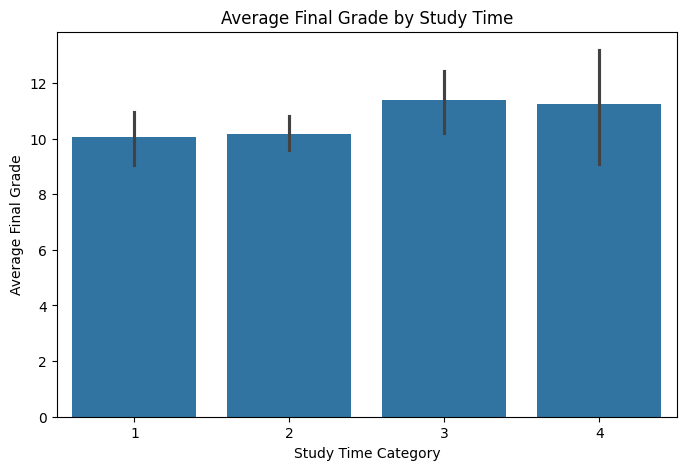

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()

In [12]:
# 1. Check dataset size and column names
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# 2. Check missing values and duplicate rows
print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

# 3. Summary of final grades
print("\nFinal grade (G3) summary:")
print(df["G3"].describe())

print("\nAverage final grade:", round(df["G3"].mean(), 2))

Dataset shape: (395, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing values:
0

Duplicate rows:
0

Final grade (G3) summary:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Average final grade: 10.42


In [13]:
df["Result"] = df["G3"].apply(
    lambda grade: "Pass" if grade >= 10 else "Fail"
)

print(df["Result"].value_counts())

Result
Pass    265
Fail    130
Name: count, dtype: int64


In [14]:
print(
    df.groupby("studytime")["G3"].mean()
)

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64


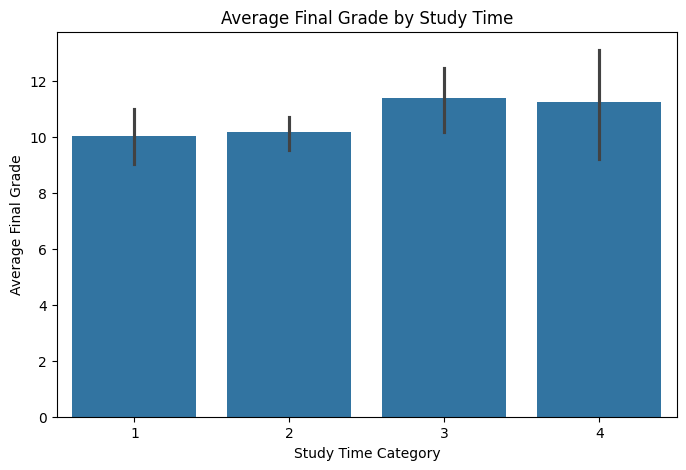

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")

plt.show()

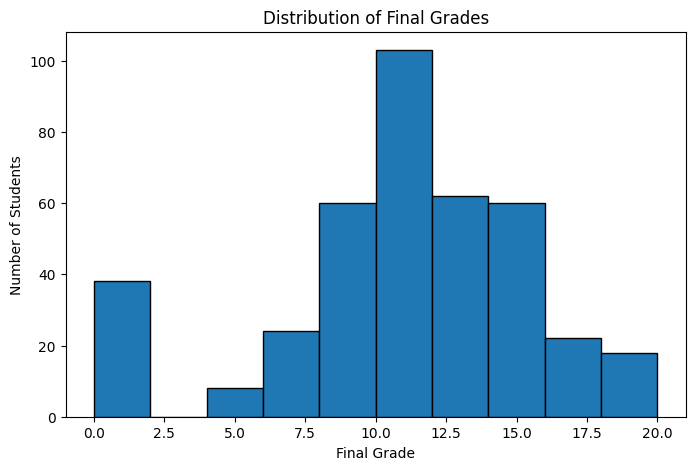

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(df["G3"], bins=10, edgecolor="black")

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

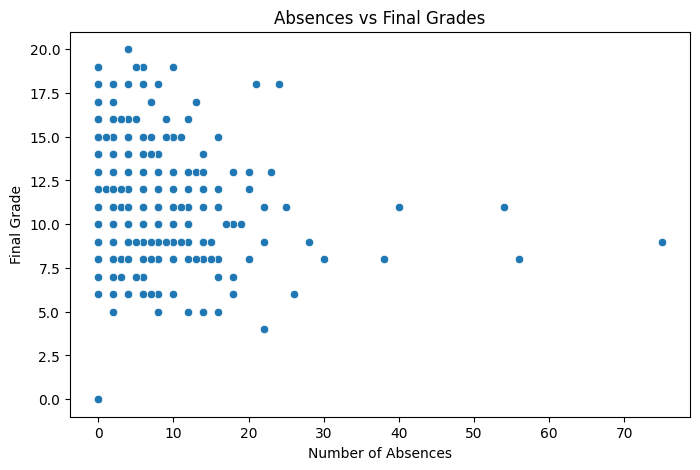

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grades")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")

plt.show()

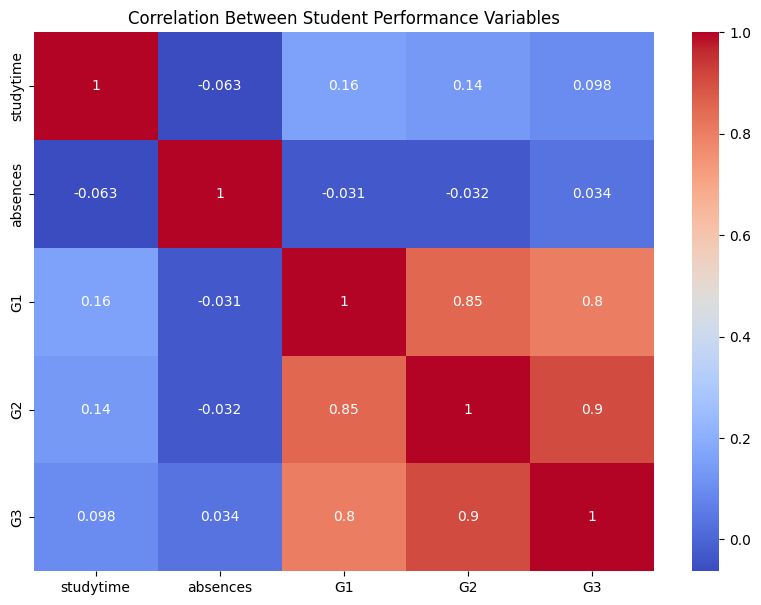

In [18]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[["studytime", "absences", "G1", "G2", "G3"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Student Performance Variables")
plt.show()

In [19]:
print("Average Final Grade:", df["G3"].mean())

print("\nAverage Grade by Study Time:")
print(df.groupby("studytime")["G3"].mean())

print("\nAverage Grade by Result:")
print(df.groupby("Result")["G3"].mean())

print("\nCorrelation with Final Grade:")
print(df[["studytime", "absences", "G1", "G2", "G3"]].corr()["G3"])

Average Final Grade: 10.415189873417722

Average Grade by Study Time:
studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

Average Grade by Result:
Result
Fail     5.384615
Pass    12.883019
Name: G3, dtype: float64

Correlation with Final Grade:
studytime    0.097820
absences     0.034247
G1           0.801468
G2           0.904868
G3           1.000000
Name: G3, dtype: float64


Project conclusion

This project analyzes student academic performance using Python, Pandas, Matplotlib, and Seaborn.

The dataset was explored and cleaned before performing statistical analysis. Different visualizations were created to understand the distribution of final grades and the relationship between study time, absences, and academic performance.

The project helped me understand how real-world data can be analyzed to identify patterns and generate meaningful insights.